# Punto 1: clasificación de parches de imagen con aprendizaje no supervisado

Este cuadernillo clasifica parches de `64 x 64` extraídos de las imágenes
originales. A diferencia de la versión anterior, los parches se mantienen en
**RGB** y se describen con características de **color y textura**, no con
píxeles crudos en escala de grises.

Flujo:

1. Inventario, detección de duplicados y separación por escenas.
2. Extracción de parches RGB y cálculo de características.
3. `MiniBatchKMeans` con varios `k` y elección del mejor `k` por el **codo**.
4. Etiquetado manual de un representante por cluster.
5. Etiquetado manual de parches de prueba.
6. Propagación semi-supervisada y regresión logística.
7. Aprendizaje activo comparado con muestreo aleatorio.
8. Figuras de distribución de clusters, PCA, métricas y matriz de confusión.

Clases: `agua`, `basura`, `muro`, `roca`, `terreno`, `vegetacion`.
La etiqueta `dudoso` se usa para parches ambiguos y se excluye del entrenamiento.

In [1]:
import os
import io
import hashlib
import json
import math
import unicodedata
import warnings
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display
from matplotlib.patches import Patch, Rectangle
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    classification_report,
    confusion_matrix,
    normalized_mutual_info_score,
    precision_recall_fscore_support,
    silhouette_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

try:
    import pillow_heif

    pillow_heif.register_heif_opener()
    HEIF_DISPONIBLE = True
except Exception:
    HEIF_DISPONIBLE = False

MODO_PRUEBA = os.environ.get("P1_MODO_PRUEBA", "0") == "1"

RAIZ = Path.cwd()
if not (RAIZ / "maria_luciana_salinas_vilar").exists():
    RAIZ = Path("/home/zahir/IA1/part2")
CARPETA_IMAGENES = RAIZ / "maria_luciana_salinas_vilar"

TAM_PARCHE = 64
MAX_PARCHES_POR_IMAGEN = 64
MIN_STD_PARCHE = 5.0
SEMILLA = 42
K_MIN = 2
K_MAX = 20
TEST_SIZE = 0.2
MUESTRA_SILUETA = 2000
OBJETIVO_ETIQUETAS = 86
N_ACTIVO = 8
REPETICIONES_ACTIVO = 2
N_COBERTURA = 8
GAP_ESCENA = 120
UMBRAL_DUPLICADO = 1
CLASES_BASE = ["agua", "basura", "muro", "roca", "terreno", "vegetacion"]
CLASES = list(CLASES_BASE)

if MODO_PRUEBA:
    SALIDA = Path("/tmp/opencode/resultados_p1_prueba")
    MAX_IMAGENES = 24
    PARCHES_POR_IMAGEN = 4
    K_MAX = 5
    MUESTRA_SILUETA = 500
    OBJETIVO_ETIQUETAS = 24
    N_ACTIVO = 3
    REPETICIONES_ACTIVO = 1
    N_COBERTURA = 0
    SIN_CACHE = True
else:
    SALIDA = RAIZ / "resultados_p1"
    MAX_IMAGENES = None
    PARCHES_POR_IMAGEN = MAX_PARCHES_POR_IMAGEN
    SIN_CACHE = False

FIGURAS = SALIDA / "figuras"
CACHE = SALIDA / "cache"
ETIQUETAS_REPRESENTANTES = SALIDA / "etiquetas_representantes.csv"
ETIQUETAS_TEST = SALIDA / "etiquetas_test.csv"
ETIQUETAS_COBERTURA = SALIDA / "etiquetas_cobertura.csv"
ETIQUETAS_ACTIVO = SALIDA / "etiquetas_activo.csv"
ETIQUETAS_ALEATORIO = SALIDA / "etiquetas_aleatorio.csv"
RUTA_CLASES = SALIDA / "clases.txt"

SALIDA.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)


def normalizar_clase(texto):
    texto = str(texto).strip().lower()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return " ".join(texto.split())


def guardar_clases(clases, ruta):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    limpias = []
    for clase in clases:
        c = normalizar_clase(clase)
        if c and c not in limpias:
            limpias.append(c)
    ruta.write_text("\n".join(limpias) + "\n", encoding="utf-8")
    return ruta


if RUTA_CLASES.exists():
    for linea in RUTA_CLASES.read_text(encoding="utf-8").splitlines():
        clase = normalizar_clase(linea)
        if clase and clase not in CLASES:
            CLASES.append(clase)

if not MODO_PRUEBA:
    for ruta_csv in [
        ETIQUETAS_REPRESENTANTES,
        ETIQUETAS_TEST,
        ETIQUETAS_COBERTURA,
        ETIQUETAS_ACTIVO,
        ETIQUETAS_ALEATORIO,
    ]:
        if ruta_csv.exists():
            df_clases = pd.read_csv(ruta_csv, dtype=str, keep_default_na=False)
            if "clase" in df_clases.columns:
                for clase in df_clases["clase"]:
                    c = normalizar_clase(clase)
                    if c and c != "dudoso" and c not in CLASES:
                        CLASES.append(c)

limpias = []
for clase in CLASES:
    c = normalizar_clase(clase)
    if c and c not in limpias:
        limpias.append(c)
CLASES[:] = limpias
guardar_clases(CLASES, RUTA_CLASES)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

print(f"Modo de prueba: {MODO_PRUEBA}")
print(f"Carpeta de imágenes: {CARPETA_IMAGENES}")
print(f"Salida: {SALIDA}")
print(f"HEIF disponible: {HEIF_DISPONIBLE}")
print(f"Clases: {CLASES}")


def guardar_fig(ruta):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(ruta, bbox_inches="tight")
    print(f"Figura guardada en: {ruta}")
    return ruta


def cargar_rgb(ruta):
    ruta = Path(ruta)
    with Image.open(ruta) as img:
        img = ImageOps.exif_transpose(img)
        return img.convert("RGB")


def cargar_parche_rgb(archivo, y, x):
    imagen = cargar_rgb(CARPETA_IMAGENES / archivo)
    parche = imagen.crop((int(x), int(y), int(x) + TAM_PARCHE, int(y) + TAM_PARCHE))
    return np.asarray(parche, dtype=np.uint8)


def guardar_etiquetas(df, ruta):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    columnas = [
        c
        for c in [
            "cluster",
            "indice",
            "archivo",
            "y",
            "x",
            "n_patches",
            "prediccion",
            "confianza",
            "margen",
            "clase",
        ]
        if c in df.columns
    ]
    df[columnas].to_csv(ruta, index=False, encoding="utf-8")
    return ruta


def cargar_etiquetas(ruta, df, clave):
    df = df.copy().reset_index(drop=True)
    ruta = Path(ruta)
    if not ruta.exists():
        return df
    guardadas = pd.read_csv(ruta, dtype=str, keep_default_na=False)
    guardadas.columns = [c.strip().lower() for c in guardadas.columns]
    if clave not in guardadas.columns or "clase" not in guardadas.columns:
        return df
    guardadas[clave] = guardadas[clave].astype(int)
    mapa_clase = dict(
        zip(guardadas[clave], guardadas["clase"].astype(str).str.strip())
    )
    df["clase"] = (
        df[clave].map(mapa_clase).fillna(df["clase"]).astype(str).str.strip()
    )
    for columna in ["indice", "archivo", "y", "x", "n_patches", "prediccion", "confianza", "margen"]:
        if columna in guardadas.columns and columna in df.columns:
            mapa_columna = dict(zip(guardadas[clave], guardadas[columna]))
            df[columna] = df[clave].map(mapa_columna).fillna(df[columna])
    for columna in ["indice", "y", "x", "n_patches"]:
        if columna in df.columns:
            df[columna] = pd.to_numeric(df[columna], errors="coerce").fillna(-1).astype(int)
    for columna in ["confianza", "margen"]:
        if columna in df.columns:
            df[columna] = pd.to_numeric(df[columna], errors="coerce").fillna(0.0).astype(float)
    return df


def mostrar_parche_contexto(archivo, y, x, titulo=""):
    imagen = cargar_rgb(CARPETA_IMAGENES / archivo)
    parche = imagen.crop((int(x), int(y), int(x) + TAM_PARCHE, int(y) + TAM_PARCHE))
    contexto = imagen.copy()
    dibujo = ImageDraw.Draw(contexto)
    dibujo.rectangle(
        [int(x), int(y), int(x) + TAM_PARCHE - 1, int(y) + TAM_PARCHE - 1],
        outline="red",
        width=6,
    )
    contexto.thumbnail((900, 900), Image.Resampling.LANCZOS)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(parche)
    axes[0].set_title("Parche 64x64")
    axes[0].axis("off")
    axes[1].imshow(contexto)
    axes[1].set_title(str(archivo), fontsize=8)
    axes[1].axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def etiquetar_lote_prompt(df, ruta_salida, clave, titulo, clases, columnas_extra=None):
    df = cargar_etiquetas(ruta_salida, df, clave)
    for i in range(len(df)):
        clase_actual = str(df.at[i, "clase"]).strip()
        if clase_actual:
            continue
        fila = df.iloc[i]
        print(
            f"\n[{i + 1}/{len(df)}] {titulo} | cluster {fila.get('cluster', '')} | "
            f"{fila['archivo']} y={int(fila['y'])} x={int(fila['x'])}"
        )
        if columnas_extra:
            for columna in columnas_extra:
                if columna in fila.index:
                    print(f"  {columna}: {fila[columna]}")
        mostrar_parche_contexto(
            fila["archivo"],
            int(fila["y"]),
            int(fila["x"]),
            titulo=f"{titulo} {i + 1}/{len(df)}",
        )
        while True:
            texto = normalizar_clase(
                input(
                    f"Clase {clases} o nueva (Enter=saltar, d=dudoso, s=salir): "
                )
            )
            if texto == "s":
                guardar_etiquetas(df, ruta_salida)
                return df
            if texto == "":
                break
            if texto in {"d", "dudoso"}:
                df.at[i, "clase"] = "dudoso"
                guardar_etiquetas(df, ruta_salida)
                break
            if texto not in clases:
                clases.append(texto)
                guardar_clases(clases, RUTA_CLASES)
                print(f"Clase agregada: {texto}")
            df.at[i, "clase"] = texto
            guardar_etiquetas(df, ruta_salida)
            break
    guardar_etiquetas(df, ruta_salida)
    return df


def etiquetar_representantes_prompt(df_reps, candidatos, ruta_salida, clases):
    df_reps = cargar_etiquetas(ruta_salida, df_reps, "cluster")
    for i in range(len(df_reps)):
        cluster = int(df_reps.at[i, "cluster"])
        lista = candidatos.get(cluster, [])
        if not lista:
            continue
        posicion = 0
        while True:
            candidato = lista[posicion]
            df_reps.at[i, "indice"] = int(candidato["indice"])
            df_reps.at[i, "archivo"] = str(candidato["archivo"])
            df_reps.at[i, "y"] = int(candidato["y"])
            df_reps.at[i, "x"] = int(candidato["x"])
            clase_actual = str(df_reps.at[i, "clase"]).strip()
            print(
                f"\nCluster {cluster} | candidato {posicion + 1}/{len(lista)} | "
                f"{candidato['archivo']} y={candidato['y']} x={candidato['x']} | "
                f"clase actual: {clase_actual if clase_actual else '(sin etiquetar)'}"
            )
            mostrar_parche_contexto(
                candidato["archivo"],
                candidato["y"],
                candidato["x"],
                titulo=f"Cluster {cluster} | {posicion + 1}/{len(lista)}",
            )
            texto = normalizar_clase(
                input(
                    f"Clase {clases} o nueva (Enter=saltar, n=siguiente, d=dudoso, s=salir): "
                )
            )
            if texto == "s":
                guardar_etiquetas(df_reps, ruta_salida)
                return df_reps
            if texto == "n":
                posicion = (posicion + 1) % len(lista)
                continue
            if texto == "":
                break
            if texto in {"d", "dudoso"}:
                df_reps.at[i, "clase"] = "dudoso"
                guardar_etiquetas(df_reps, ruta_salida)
                break
            if texto not in clases:
                clases.append(texto)
                guardar_clases(clases, RUTA_CLASES)
                print(f"Clase agregada: {texto}")
            df_reps.at[i, "clase"] = texto
            guardar_etiquetas(df_reps, ruta_salida)
            break
    guardar_etiquetas(df_reps, ruta_salida)
    return df_reps

Modo de prueba: False
Carpeta de imágenes: /home/zahir/IA1/part2/maria_luciana_salinas_vilar
Salida: /home/zahir/IA1/part2/resultados_p1
HEIF disponible: True
Clases: ['agua', 'basura', 'muro', 'roca', 'terreno', 'vegetacion']


## 1. Inventario y separación por escenas

In [2]:
EXTENSIONES_IMAGEN = {".heic", ".jpg", ".jpeg", ".png"}


def leer_fecha(img, ruta):
    exif = img.getexif()
    for clave in (36867, 306):
        valor = exif.get(clave)
        if valor:
            texto = str(valor).strip()
            for formato in ("%Y:%m:%d %H:%M:%S", "%Y-%m-%d %H:%M:%S"):
                try:
                    return datetime.strptime(texto, formato)
                except ValueError:
                    pass
    return datetime.fromtimestamp(Path(ruta).stat().st_mtime)


def hash_promedio(img):
    pequena = img.convert("L").resize((8, 8), Image.Resampling.LANCZOS)
    arreglo = np.asarray(pequena, dtype=np.float32)
    return (arreglo > arreglo.mean()).reshape(-1)


def distancia_hamming(a, b):
    return int(np.count_nonzero(a != b))


def inventariar(carpeta, umbral_duplicado=UMBRAL_DUPLICADO, gap_escena=GAP_ESCENA):
    carpeta = Path(carpeta)
    archivos = sorted(
        p
        for p in carpeta.iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSIONES_IMAGEN
    )
    registros = []
    duplicados = []
    hashes = []
    total = len(archivos)
    for posicion, ruta in enumerate(archivos, start=1):
        img = cargar_rgb(ruta)
        fecha = leer_fecha(img, ruta)
        huella = hash_promedio(img)
        duplicado_de = None
        for anterior_huella, anterior_nombre in hashes:
            if distancia_hamming(huella, anterior_huella) <= umbral_duplicado:
                duplicado_de = anterior_nombre
                break
        if duplicado_de is not None:
            duplicados.append(
                {
                    "archivo": ruta.name,
                    "duplicado_de": duplicado_de,
                    "fecha": fecha.strftime("%Y-%m-%d %H:%M:%S"),
                }
            )
        else:
            hashes.append((huella, ruta.name))
            registros.append(
                {
                    "archivo": ruta.name,
                    "ruta": str(ruta),
                    "fecha": fecha.strftime("%Y-%m-%d %H:%M:%S"),
                    "fecha_dt": fecha,
                }
            )
        if posicion % 20 == 0 or posicion == total:
            print(f"Inventario: {posicion}/{total} archivos procesados")
    registros.sort(key=lambda r: r["fecha_dt"])
    escena = -1
    fecha_anterior = None
    for registro in registros:
        fecha = registro["fecha_dt"]
        if fecha_anterior is None or (fecha - fecha_anterior).total_seconds() > gap_escena:
            escena += 1
        registro["escena"] = escena
        fecha_anterior = fecha
    df = pd.DataFrame(registros)
    df = df.drop(columns=["fecha_dt"])
    df_duplicados = pd.DataFrame(duplicados)
    return df, df_duplicados


if not HEIF_DISPONIBLE:
    raise RuntimeError(
        "Falta pillow-heif. Instala con: uv add pillow-heif"
    )

df_inventario, df_duplicados = inventariar(
    CARPETA_IMAGENES,
    umbral_duplicado=UMBRAL_DUPLICADO,
    gap_escena=GAP_ESCENA,
)
df_inventario.to_csv(SALIDA / "inventario.csv", index=False, encoding="utf-8")
if not df_duplicados.empty:
    df_duplicados.to_csv(SALIDA / "duplicados.csv", index=False, encoding="utf-8")

df = df_inventario.copy()
if MAX_IMAGENES is not None:
    df = df.sample(n=min(MAX_IMAGENES, len(df)), random_state=SEMILLA).copy()
    df = df.sort_values("fecha").reset_index(drop=True)

divisor = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEMILLA)
indices_pool, indices_test = next(divisor.split(df, groups=df["escena"]))
df_pool = df.iloc[indices_pool].reset_index(drop=True)
df_test = df.iloc[indices_test].reset_index(drop=True)

print("División por escenas")
print(f"Imágenes únicas          : {len(df)}")
print(f"Escenas en el pool       : {df_pool['escena'].nunique()}")
print(f"Escenas en prueba        : {df_test['escena'].nunique()}")
print(f"Imágenes en el pool      : {len(df_pool)}")
print(f"Imágenes en prueba       : {len(df_test)}")

Inventario: 20/181 archivos procesados
Inventario: 40/181 archivos procesados
Inventario: 60/181 archivos procesados
Inventario: 80/181 archivos procesados
Inventario: 100/181 archivos procesados
Inventario: 120/181 archivos procesados
Inventario: 140/181 archivos procesados
Inventario: 160/181 archivos procesados
Inventario: 180/181 archivos procesados
Inventario: 181/181 archivos procesados
División por escenas
Imágenes únicas          : 173
Escenas en el pool       : 8
Escenas en prueba        : 3
Imágenes en el pool      : 136
Imágenes en prueba       : 37


## 2. Extracción de parches RGB y características de color y textura

Cada parche de `64 x 64` se describe con histogramas HSV, momentos de color y
medidas de textura (Sobel, Laplaciano, desviación local, entropía y bordes).
La caché guarda solo las características y las coordenadas; para mostrar un
parche se recorta de la imagen original.

In [3]:
def extraer_caracteristicas_parche(parche_rgb):
    parche = parche_rgb.astype(np.uint8)
    hsv = cv2.cvtColor(parche, cv2.COLOR_RGB2HSV)
    gris = cv2.cvtColor(parche, cv2.COLOR_RGB2GRAY)

    histogramas = []
    for canal, bins, rango in zip(
        [hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]],
        [18, 16, 16],
        [(0, 180), (0, 256), (0, 256)],
    ):
        histograma, _ = np.histogram(canal, bins=bins, range=rango)
        histograma = histograma.astype(np.float32)
        histograma /= max(1.0, float(histograma.sum()))
        histogramas.append(histograma)
    color_hist = np.concatenate(histogramas)

    rgb = parche.astype(np.float32) / 255.0
    hsv_f = hsv.astype(np.float32)
    hsv_f[:, :, 0] /= 180.0
    hsv_f[:, :, 1] /= 255.0
    hsv_f[:, :, 2] /= 255.0

    momentos = []
    for canal in [
        rgb[:, :, 0],
        rgb[:, :, 1],
        rgb[:, :, 2],
        hsv_f[:, :, 0],
        hsv_f[:, :, 1],
        hsv_f[:, :, 2],
    ]:
        momentos.extend([float(canal.mean()), float(canal.std())])

    gx = cv2.Sobel(gris, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gris, cv2.CV_32F, 0, 1, ksize=3)
    magnitud = cv2.magnitude(gx, gy)
    textura = [
        float(magnitud.mean()),
        float(magnitud.std()),
        float(np.percentile(magnitud, 90)),
    ]

    laplaciano = cv2.Laplacian(gris, cv2.CV_32F)
    textura.append(float(laplaciano.var()))

    bloques = gris.reshape(8, 8, 8, 8).astype(np.float32)
    std_bloques = bloques.std(axis=(2, 3))
    textura.extend([float(std_bloques.mean()), float(std_bloques.std())])

    hist_gris, _ = np.histogram(gris, bins=32, range=(0, 256))
    probabilidades = hist_gris.astype(np.float32)
    probabilidades /= max(1.0, float(probabilidades.sum()))
    entropia = float(
        -np.sum(probabilidades[probabilidades > 0] * np.log2(probabilidades[probabilidades > 0]))
    )
    textura.append(entropia)

    bordes = cv2.Canny(gris, 50, 150)
    textura.append(float(bordes.mean() / 255.0))

    vector = np.concatenate(
        [
            color_hist,
            np.asarray(momentos, dtype=np.float32),
            np.asarray(textura, dtype=np.float32),
        ]
    )
    return vector.astype(np.float32)


def extraer_parches_imagen(ruta, n_parches, semilla, min_std):
    img = cargar_rgb(ruta)
    arreglo = np.asarray(img, dtype=np.uint8)
    alto, ancho = arreglo.shape[:2]
    lado = int(math.ceil(math.sqrt(n_parches)))
    rng = np.random.default_rng(semilla)

    caracteristicas = []
    coordenadas = []
    for ry in range(lado):
        for rx in range(lado):
            y0 = int(ry * alto / lado)
            y1 = int((ry + 1) * alto / lado)
            x0 = int(rx * ancho / lado)
            x1 = int((rx + 1) * ancho / lado)
            max_y = y1 - TAM_PARCHE
            max_x = x1 - TAM_PARCHE
            if max_y <= y0 or max_x <= x0:
                cy = max(0, (y0 + y1 - TAM_PARCHE) // 2)
                cx = max(0, (x0 + x1 - TAM_PARCHE) // 2)
            else:
                cy = int(rng.integers(y0, max_y + 1))
                cx = int(rng.integers(x0, max_x + 1))
            parche = arreglo[cy : cy + TAM_PARCHE, cx : cx + TAM_PARCHE]
            if parche.shape != (TAM_PARCHE, TAM_PARCHE, 3):
                continue
            gris = cv2.cvtColor(parche, cv2.COLOR_RGB2GRAY)
            if float(gris.std()) >= min_std:
                caracteristicas.append(extraer_caracteristicas_parche(parche))
                coordenadas.append((cy, cx))

    if not caracteristicas:
        for ry in range(lado):
            for rx in range(lado):
                y0 = int(ry * alto / lado)
                y1 = int((ry + 1) * alto / lado)
                x0 = int(rx * ancho / lado)
                x1 = int((rx + 1) * ancho / lado)
                parche = arreglo[y0 : y0 + TAM_PARCHE, x0 : x0 + TAM_PARCHE]
                if parche.shape == (TAM_PARCHE, TAM_PARCHE, 3):
                    caracteristicas.append(extraer_caracteristicas_parche(parche))
                    coordenadas.append((y0, x0))

    if len(caracteristicas) > n_parches:
        elegidos = np.sort(rng.choice(len(caracteristicas), size=n_parches, replace=False))
        caracteristicas = [caracteristicas[i] for i in elegidos]
        coordenadas = [coordenadas[i] for i in elegidos]

    return np.vstack(caracteristicas).astype(np.float32), np.asarray(
        coordenadas, dtype=np.int32
    )


def construir_matriz(df, n_parches, min_std, semilla):
    partes_x = []
    archivos = []
    partes_coords = []
    total = len(df)
    for posicion, fila in enumerate(df.itertuples(index=False), start=1):
        x, coords = extraer_parches_imagen(
            fila.ruta,
            n_parches=n_parches,
            semilla=semilla + posicion,
            min_std=min_std,
        )
        partes_x.append(x)
        archivos.extend([fila.archivo] * len(x))
        partes_coords.append(coords)
        if posicion % 10 == 0 or posicion == total:
            print(f"Parches: {posicion}/{total} imágenes procesadas")
    return (
        np.vstack(partes_x).astype(np.float32),
        np.asarray(archivos),
        np.vstack(partes_coords).astype(np.int32),
    )


def clave_cache(lista_archivos, parametros):
    texto = ",".join(lista_archivos) + repr(sorted(parametros.items()))
    return hashlib.sha1(texto.encode("utf-8")).hexdigest()[:16]


def cargar_o_construir_matriz(df, cache_dir, n_parches, min_std, semilla, usar_cache):
    parametros = {
        "version": "color_textura_v1",
        "modo": "rgb",
        "tam_parche": TAM_PARCHE,
        "n_parches": int(n_parches),
        "min_std": float(min_std),
        "semilla": int(semilla),
        "n_imagenes": int(len(df)),
    }
    ruta_cache = (
        Path(cache_dir)
        / f"caracteristicas_{clave_cache(df['archivo'].astype(str), parametros)}.npz"
    )
    ruta_cache.parent.mkdir(parents=True, exist_ok=True)
    if usar_cache and ruta_cache.exists():
        datos = np.load(ruta_cache, allow_pickle=False)
        print(f"Caché cargado desde: {ruta_cache}")
        return datos["X"], datos["archivos"], datos["coords"]
    x_total, archivos_total, coords_total = construir_matriz(
        df, n_parches=n_parches, min_std=min_std, semilla=semilla
    )
    if usar_cache:
        np.savez_compressed(
            ruta_cache,
            X=x_total,
            archivos=archivos_total,
            coords=coords_total,
        )
        print(f"Caché guardado en: {ruta_cache}")
    return x_total, archivos_total, coords_total


X_pool, archivos_pool, coords_pool = cargar_o_construir_matriz(
    df_pool,
    cache_dir=CACHE,
    n_parches=PARCHES_POR_IMAGEN,
    min_std=MIN_STD_PARCHE,
    semilla=SEMILLA,
    usar_cache=not SIN_CACHE,
)
X_test, archivos_test, coords_test = cargar_o_construir_matriz(
    df_test,
    cache_dir=CACHE,
    n_parches=PARCHES_POR_IMAGEN,
    min_std=MIN_STD_PARCHE,
    semilla=SEMILLA + 1000,
    usar_cache=not SIN_CACHE,
)

scaler = StandardScaler()
X_pool_esc = scaler.fit_transform(X_pool).astype(np.float32)
X_test_esc = scaler.transform(X_test).astype(np.float32)

print("Matrices de características")
print(f"X_pool: {X_pool.shape} | X_test: {X_test.shape}")
print(f"Características por parche: {X_pool.shape[1]}")
print(f"Parches del pool: {len(X_pool)} | Parches de prueba: {len(X_test)}")

Caché cargado desde: /home/zahir/IA1/part2/resultados_p1/cache/caracteristicas_4a90ac8505da351c.npz
Caché cargado desde: /home/zahir/IA1/part2/resultados_p1/cache/caracteristicas_c73161be9c2446ab.npz
Matrices de características
X_pool: (8574, 70) | X_test: (2284, 70)
Características por parche: 70
Parches del pool: 8574 | Parches de prueba: 2284


## 3. Selección de `k` por el codo

Se evalúan todos los `k` entre `K_MIN` y `K_MAX`. El criterio principal es el
**codo de la inercia**; la silueta se usa como diagnóstico secundario. Luego se
fija un mínimo de 6 clusters, porque hay 6 clases semánticas.

k= 2 | inercia=528052.50 | silueta=0.1302
k= 3 | inercia=477347.72 | silueta=0.1654
k= 4 | inercia=445172.91 | silueta=0.1049
k= 5 | inercia=433121.56 | silueta=0.0486
k= 6 | inercia=411677.56 | silueta=0.0747
k= 7 | inercia=400467.22 | silueta=0.0786
k= 8 | inercia=386130.47 | silueta=0.0870
k= 9 | inercia=377781.81 | silueta=0.0673
k=10 | inercia=374843.97 | silueta=0.0676
k=11 | inercia=361362.34 | silueta=0.0895
k=12 | inercia=354838.41 | silueta=0.0672
k=13 | inercia=351932.12 | silueta=0.0809
k=14 | inercia=345950.12 | silueta=0.0553
k=15 | inercia=341172.78 | silueta=0.0800
k=16 | inercia=334562.16 | silueta=0.0678
k=17 | inercia=324462.56 | silueta=0.0799
k=18 | inercia=327017.75 | silueta=0.0576
k=19 | inercia=317362.84 | silueta=0.0775
k=20 | inercia=313565.53 | silueta=0.0716

Codo detectado: k=8
k elegido: 8
Figura guardada en: /home/zahir/IA1/part2/resultados_p1/figuras/p1_seleccion_k.png


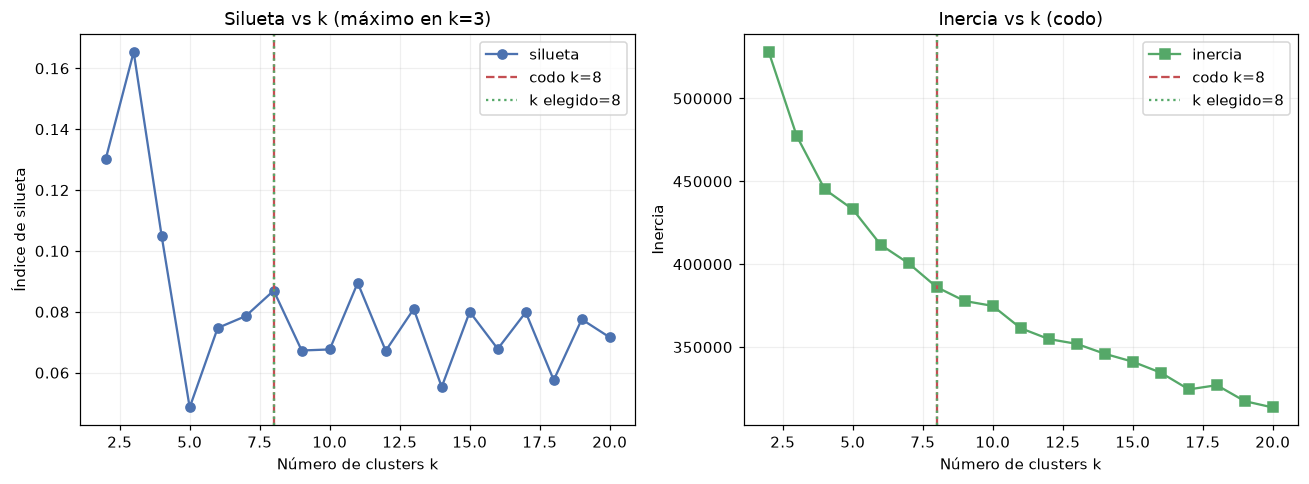

In [4]:
def nuevo_minibatch(k, semilla, n_muestras):
    return MiniBatchKMeans(
        n_clusters=int(k),
        init="k-means++",
        random_state=semilla,
        batch_size=int(min(2048, max(1, n_muestras))),
        n_init=10,
        max_iter=300,
        reassignment_ratio=0.0,
    )


def evaluar_k(x, k_min, k_max, semilla, muestra_silueta):
    k_max = int(min(k_max, len(x) - 1))
    k_min = int(max(2, k_min))
    if k_max < k_min:
        raise RuntimeError("No hay suficientes muestras para evaluar K-Means")
    filas = []
    modelos = {}
    for k in range(k_min, k_max + 1):
        modelo = nuevo_minibatch(k, semilla, len(x)).fit(x)
        etiquetas = modelo.labels_
        tam = int(min(muestra_silueta, len(x)))
        silueta = float(
            silhouette_score(x, etiquetas, sample_size=tam, random_state=semilla)
        )
        filas.append({"k": k, "inercia": float(modelo.inertia_), "silueta": silueta})
        modelos[k] = modelo
        print(f"k={k:2d} | inercia={modelo.inertia_:.2f} | silueta={silueta:.4f}")
    df = pd.DataFrame(filas)
    return df, modelos


def detectar_codo(df):
    x = df["k"].to_numpy(dtype=float)
    y = df["inercia"].to_numpy(dtype=float)
    x_norm = (x - x.min()) / max(1e-12, x.max() - x.min())
    y_norm = (y - y.min()) / max(1e-12, y.max() - y.min())
    puntos = np.column_stack([x_norm, y_norm])
    inicio = np.array([x_norm[0], y_norm[0]])
    fin = np.array([x_norm[-1], y_norm[-1]])
    vector = fin - inicio
    norma = max(1e-12, float(np.linalg.norm(vector)))
    distancias = np.abs(
        vector[0] * (puntos[:, 1] - inicio[1])
        - vector[1] * (puntos[:, 0] - inicio[0])
    ) / norma
    return int(x[int(np.argmax(distancias))])


def graficar_seleccion_k(df, k_codo, k_elegido, ruta):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(df["k"], df["silueta"], "o-", color="#4c72b0", label="silueta")
    max_silueta = int(df.loc[df["silueta"].idxmax(), "k"])
    axes[0].axvline(k_codo, color="#c44e52", linestyle="--", label=f"codo k={k_codo}")
    axes[0].axvline(k_elegido, color="#55a868", linestyle=":", label=f"k elegido={k_elegido}")
    axes[0].set_xlabel("Número de clusters k")
    axes[0].set_ylabel("Índice de silueta")
    axes[0].set_title(f"Silueta vs k (máximo en k={max_silueta})")
    axes[0].legend()
    axes[1].plot(df["k"], df["inercia"], "s-", color="#55a868", label="inercia")
    axes[1].axvline(k_codo, color="#c44e52", linestyle="--", label=f"codo k={k_codo}")
    axes[1].axvline(k_elegido, color="#55a868", linestyle=":", label=f"k elegido={k_elegido}")
    axes[1].set_xlabel("Número de clusters k")
    axes[1].set_ylabel("Inercia")
    axes[1].set_title("Inercia vs k (codo)")
    axes[1].legend()
    plt.tight_layout()
    return guardar_fig(ruta)


df_k, modelos_k = evaluar_k(
    X_pool_esc, K_MIN, K_MAX, SEMILLA, MUESTRA_SILUETA
)
k_codo = detectar_codo(df_k)
k_elegido = min(max(int(k_codo), 6), K_MAX)
df_k.to_csv(SALIDA / "seleccion_k.csv", index=False, encoding="utf-8")

print(f"\nCodo detectado: k={k_codo}")
print(f"k elegido: {k_elegido}")

graficar_seleccion_k(
    df_k, k_codo, k_elegido, FIGURAS / "p1_seleccion_k.png"
)
plt.show()
plt.close("all")

## 4. Entrenamiento final y distribución de clusters

Se entrena `MiniBatchKMeans` con el `k` elegido y se guardan las figuras de
distribución de clusters, PCA coloreado por cluster, representantes y parches
por cluster.

### Etiquetado de representantes

Clases iniciales: `agua`, `basura`, `muro`, `roca`, `terreno`, `vegetacion`,
`dudoso`. Si escribes una clase que no está en la lista, se agrega
automáticamente y queda guardada en `resultados_p1/clases.txt`.

Para cada cluster verás el parche ampliado y la foto completa con el recuadro.
Escribe la clase y pulsa Enter. Opciones:

- Enter vacío: saltar el cluster.
- `n`: ver el siguiente candidato del mismo cluster.
- `d`: marcar como dudoso (no se usa para entrenar).
- `s`: salir y guardar.

Etiqueta un representante claro por cluster. Si un cluster mezcla clases, usa
`n` para buscar otro parche. El progreso se guarda en
`resultados_p1/etiquetas_representantes.csv`.

MiniBatchKMeans final con k=8
Silueta del pool: 0.0870
Tamaño de clusters:
0    1425
1     508
2    1439
3    1009
4    2089
5     448
6     661
7     995
Figura guardada en: /home/zahir/IA1/part2/resultados_p1/figuras/p1_distribucion_clusters.png
Figura guardada en: /home/zahir/IA1/part2/resultados_p1/figuras/p1_pca_clusters.png
Figura guardada en: /home/zahir/IA1/part2/resultados_p1/figuras/p1_parches_por_cluster.png


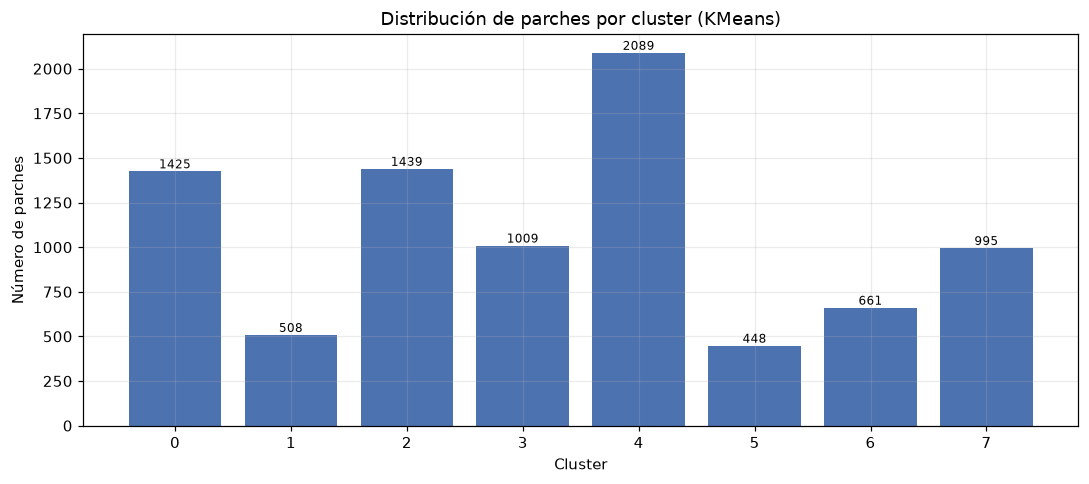

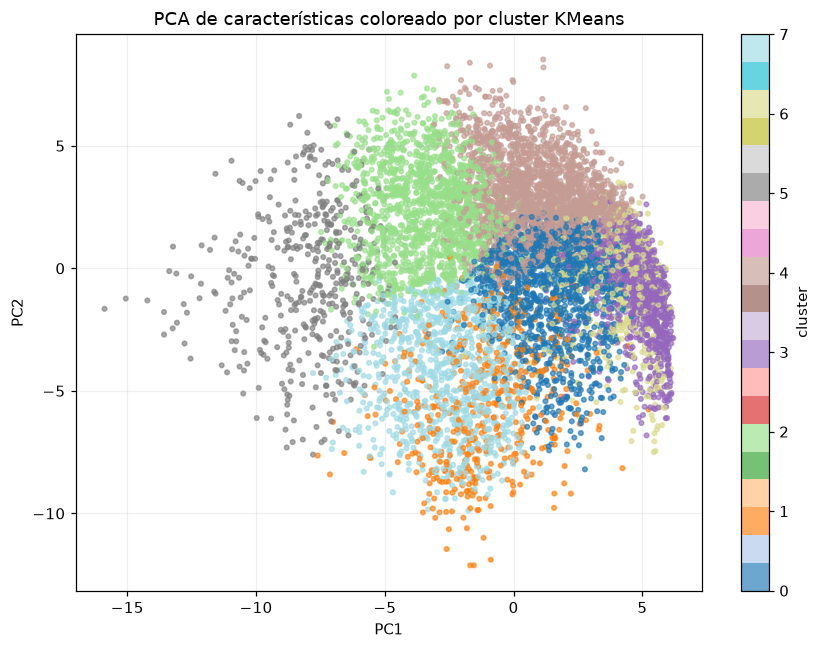

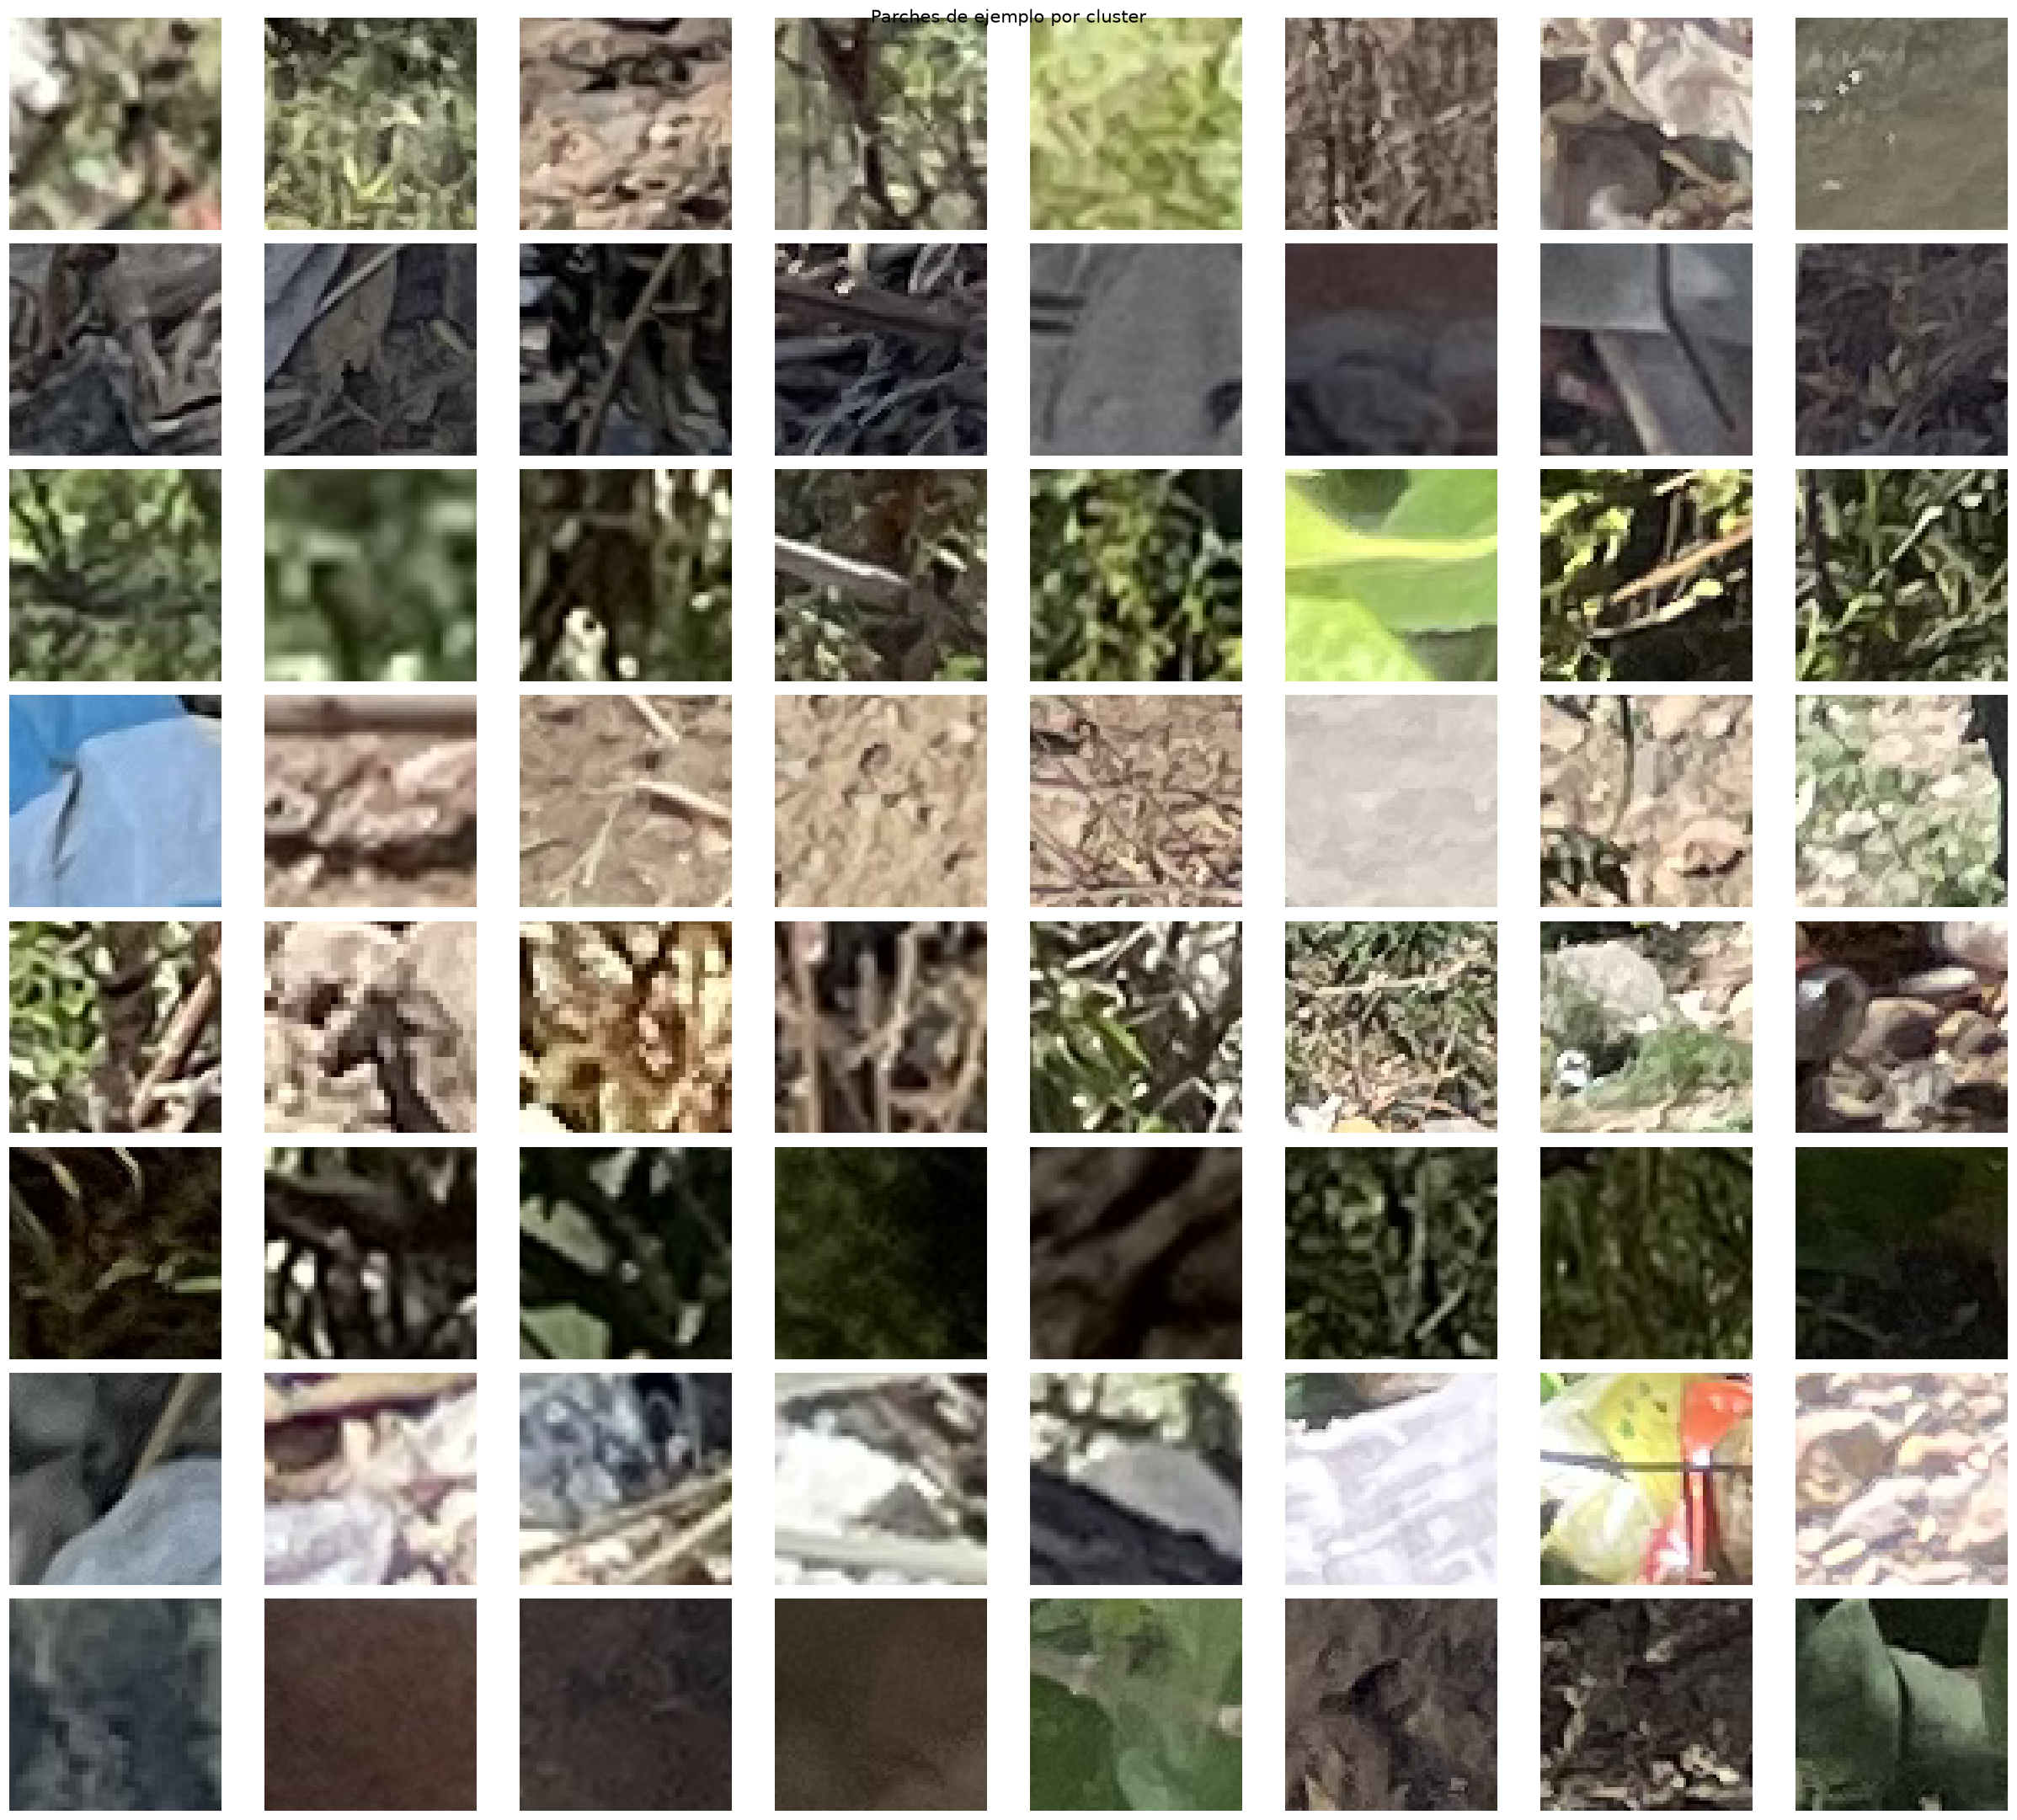

,cluster,indice,archivo,y,x,n_patches,clase
0,0,1578,IMG_3735.JPG,2606,566,1425,vegetacion
1,1,3671,IMG_3772.JPG,2453,438,508,basura
2,2,2434,IMG_3750.HEIC,1147,897,1439,vegetacion
3,3,252,IMG_3714.HEIC,239,615,1009,terreno
4,4,875,IMG_3724.HEIC,3034,1953,2089,vegetacion
5,5,4215,IMG_3783.HEIC,654,1721,448,vegetacion
6,6,6565,IMG_3851.HEIC,3055,1635,661,roca
7,7,3009,IMG_3761.JPG,1036,360,995,vegetacion



Cluster 0 | candidato 1/5 | IMG_3735.JPG y=2606 x=566 | clase actual: vegetacion


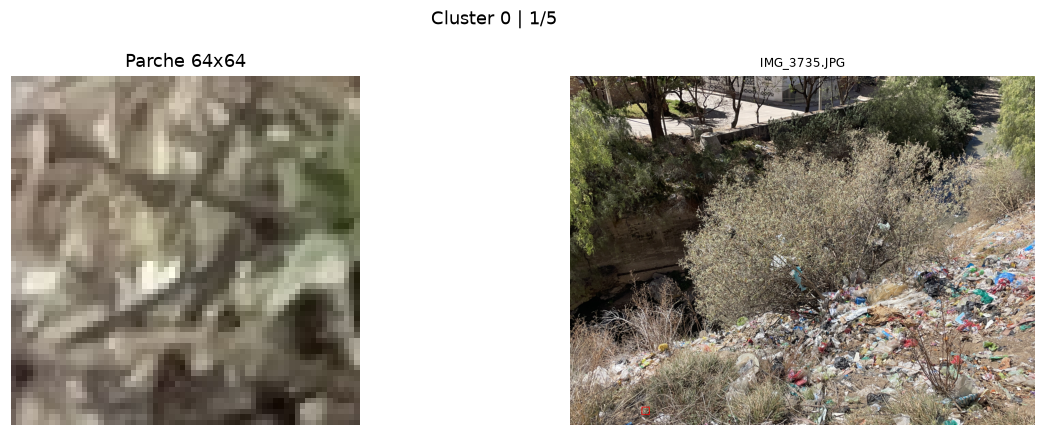

In [ ]:
kmeans = nuevo_minibatch(k_elegido, SEMILLA, len(X_pool_esc)).fit(X_pool_esc)
etiquetas_cluster = kmeans.labels_
silueta_pool = float(
    silhouette_score(
        X_pool_esc,
        etiquetas_cluster,
        sample_size=int(min(MUESTRA_SILUETA, len(X_pool_esc))),
        random_state=SEMILLA,
    )
)
conteos_cluster = np.bincount(etiquetas_cluster, minlength=kmeans.n_clusters)

print(f"MiniBatchKMeans final con k={k_elegido}")
print(f"Silueta del pool: {silueta_pool:.4f}")
print("Tamaño de clusters:")
print(pd.Series(etiquetas_cluster).value_counts().sort_index().to_string())


def obtener_representantes(modelo, x):
    distancias = modelo.transform(x)
    etiquetas = modelo.labels_
    indices = []
    for cluster in range(modelo.n_clusters):
        miembros = np.where(etiquetas == cluster)[0]
        if len(miembros) == 0:
            indices.append(-1)
        else:
            indices.append(int(miembros[np.argmin(distancias[miembros, cluster])]))
    return np.asarray(indices, dtype=int)


indices_representantes = obtener_representantes(kmeans, X_pool_esc)


def graficar_distribucion_clusters(etiquetas, ruta):
    conteo = pd.Series(etiquetas).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    barras = ax.bar(conteo.index.astype(str), conteo.values, color="#4c72b0")
    for barra, valor in zip(barras, conteo.values):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height(),
            str(int(valor)),
            ha="center",
            va="bottom",
            fontsize=8,
        )
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Número de parches")
    ax.set_title("Distribución de parches por cluster (KMeans)")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_pca_clusters(x, etiquetas, ruta):
    pca = PCA(n_components=2, random_state=SEMILLA)
    z = pca.fit_transform(x)
    fig, ax = plt.subplots(figsize=(8, 6))
    dispersion = ax.scatter(
        z[:, 0], z[:, 1], c=etiquetas, cmap="tab20", s=9, alpha=0.65
    )
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title("PCA de características coloreado por cluster KMeans")
    plt.colorbar(dispersion, ax=ax, label="cluster")
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_parches_por_cluster(archivos, coords, etiquetas, ruta, cantidad=8):
    k = int(etiquetas.max()) + 1
    rng = np.random.default_rng(SEMILLA)
    fig, axes = plt.subplots(
        k, cantidad, figsize=(2.8 * cantidad, 2.5 * k), squeeze=False
    )
    for cluster in range(k):
        miembros = np.where(etiquetas == cluster)[0]
        elegidos = miembros
        if len(miembros) > cantidad:
            elegidos = np.sort(rng.choice(miembros, size=cantidad, replace=False))
        for rank in range(cantidad):
            ax = axes[cluster, rank]
            ax.axis("off")
            if rank < len(elegidos):
                indice = int(elegidos[rank])
                parche = cargar_parche_rgb(
                    archivos[indice], coords[indice, 0], coords[indice, 1]
                )
                ax.imshow(parche)
        axes[cluster, 0].set_ylabel(f"Cluster {cluster}", fontsize=8)
    plt.suptitle("Parches de ejemplo por cluster", fontsize=14)
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_representantes(archivos, coords, indices, etiquetas, ruta):
    validos = [
        (i, int(idx), etiqueta)
        for i, (idx, etiqueta) in enumerate(zip(indices, etiquetas))
        if idx >= 0
    ]
    if not validos:
        return None
    columnas = min(6, len(validos))
    filas = int(math.ceil(len(validos) / columnas))
    fig, axes = plt.subplots(
        filas, columnas, figsize=(2.8 * columnas, 2.8 * filas), squeeze=False
    )
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (cluster, idx, etiqueta) in zip(axes.ravel(), validos):
        parche = cargar_parche_rgb(
            archivos[idx], coords[idx, 0], coords[idx, 1]
        )
        ax.imshow(parche)
        ax.set_title(f"Cluster {cluster}\n{etiqueta}", fontsize=8)
    plt.suptitle("Parches representativos de cada cluster", fontsize=14)
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_contexto_representantes(df, ruta):
    df = df.head(8)
    filas = len(df)
    fig, axes = plt.subplots(filas, 2, figsize=(11, 2.8 * filas), squeeze=False)
    for i, (_, fila) in enumerate(df.iterrows()):
        parche = cargar_parche_rgb(
            fila["archivo"], int(fila["y"]), int(fila["x"])
        )
        imagen = cargar_rgb(CARPETA_IMAGENES / str(fila["archivo"])).copy()
        dibujo = ImageDraw.Draw(imagen)
        x = int(fila["x"])
        y = int(fila["y"])
        dibujo.rectangle(
            [x, y, x + TAM_PARCHE - 1, y + TAM_PARCHE - 1],
            outline="red",
            width=6,
        )
        imagen.thumbnail((800, 800), Image.Resampling.LANCZOS)
        axes[i, 0].imshow(parche)
        axes[i, 0].set_title(
            f"C{int(fila['cluster'])} | {fila['clase']}", fontsize=9
        )
        axes[i, 0].axis("off")
        axes[i, 1].imshow(imagen)
        axes[i, 1].set_title(str(fila["archivo"]), fontsize=8)
        axes[i, 1].axis("off")
    plt.suptitle("Representantes y su ubicación en la imagen original", fontsize=14)
    plt.tight_layout()
    return guardar_fig(ruta)


graficar_distribucion_clusters(
    etiquetas_cluster, FIGURAS / "p1_distribucion_clusters.png"
)
graficar_pca_clusters(
    X_pool_esc, etiquetas_cluster, FIGURAS / "p1_pca_clusters.png"
)
graficar_parches_por_cluster(
    archivos_pool,
    coords_pool,
    etiquetas_cluster,
    FIGURAS / "p1_parches_por_cluster.png",
)
plt.show()
plt.close("all")

df_reps = pd.DataFrame(
    {
        "cluster": np.arange(kmeans.n_clusters),
        "indice": indices_representantes.astype(int),
        "archivo": [
            archivos_pool[i] if i >= 0 else "" for i in indices_representantes
        ],
        "y": [
            coords_pool[i, 0] if i >= 0 else -1 for i in indices_representantes
        ],
        "x": [
            coords_pool[i, 1] if i >= 0 else -1 for i in indices_representantes
        ],
        "n_patches": conteos_cluster.astype(int),
        "clase": "",
    }
)
df_reps = cargar_etiquetas(ETIQUETAS_REPRESENTANTES, df_reps, "cluster")

distancias_pool = kmeans.transform(X_pool_esc)
candidatos = {}
for cluster in range(kmeans.n_clusters):
    miembros = np.where(etiquetas_cluster == cluster)[0]
    orden = miembros[np.argsort(distancias_pool[miembros, cluster])][:5]
    candidatos[cluster] = [
        {
            "indice": int(i),
            "archivo": str(archivos_pool[i]),
            "y": int(coords_pool[i, 0]),
            "x": int(coords_pool[i, 1]),
        }
        for i in orden
    ]

if MODO_PRUEBA:
    df_reps["clase"] = [f"grupo_{int(c)}" for c in df_reps["cluster"]]
    guardar_etiquetas(df_reps, ETIQUETAS_REPRESENTANTES)
else:
    display(df_reps)
    df_reps = etiquetar_representantes_prompt(
        df_reps, candidatos, ETIQUETAS_REPRESENTANTES, CLASES
    )

etiquetas_reps_grafico = [
    str(df_reps.at[i, "clase"]).strip() if str(df_reps.at[i, "clase"]).strip() else f"C{int(df_reps.at[i, 'cluster'])}"
    for i in range(len(df_reps))
]
graficar_representantes(
    archivos_pool,
    coords_pool,
    df_reps["indice"].to_numpy(dtype=int),
    etiquetas_reps_grafico,
    FIGURAS / "p1_representantes.png",
)
graficar_contexto_representantes(
    df_reps, FIGURAS / "p1_contexto_representantes.png"
)
plt.show()
plt.close("all")

## 5. Etiquetado de parches de prueba

Se muestrean parches por cluster y se etiquetan manualmente. El número por
cluster se ajusta para que el total ronde las 86 etiquetas.

Para cada parche verás el recorte y la foto completa con el recuadro. Usa las
mismas opciones: Enter para saltar, `d` para dudoso y `s` para salir y guardar.
Si escribes una clase nueva, se agrega automáticamente a la lista y se guarda
en `resultados_p1/clases.txt`. Procura cubrir todas las clases; si falta
alguna, etiqueta más parches de los clusters donde aparezca. El progreso queda
en `resultados_p1/etiquetas_test.csv`.

In [ ]:
n_test_por_cluster = max(
    1,
    int(
        (
            OBJETIVO_ETIQUETAS
            - k_elegido
            - 2 * N_ACTIVO * REPETICIONES_ACTIVO
            - N_COBERTURA
        )
        / max(1, k_elegido)
    ),
)
print(
    f"k elegido={k_elegido} | representantes={k_elegido} | "
    f"prueba por cluster={n_test_por_cluster} | "
    f"prueba total≈{k_elegido * n_test_por_cluster} | "
    f"activo+aleatorio={2 * N_ACTIVO * REPETICIONES_ACTIVO} | "
    f"cobertura≤{N_COBERTURA}"
)
etiquetas_test_pred = kmeans.predict(X_test_esc)
indices_test = []
for cluster in range(kmeans.n_clusters):
    miembros = np.where(etiquetas_test_pred == cluster)[0]
    if len(miembros) == 0:
        continue
    rng_cluster = np.random.default_rng(SEMILLA + 1 + cluster)
    elegidos = rng_cluster.choice(
        miembros,
        size=min(n_test_por_cluster, len(miembros)),
        replace=False,
    )
    indices_test.append(elegidos)
indices_test = np.sort(np.concatenate(indices_test).astype(int)) if indices_test else np.array([], dtype=int)

df_test_parches = pd.DataFrame(
    {
        "indice": indices_test,
        "cluster": etiquetas_test_pred[indices_test].astype(int),
        "archivo": archivos_test[indices_test].astype(str),
        "y": coords_test[indices_test, 0].astype(int),
        "x": coords_test[indices_test, 1].astype(int),
        "clase": "",
    }
)
df_test_parches = cargar_etiquetas(ETIQUETAS_TEST, df_test_parches, "indice")

if MODO_PRUEBA:
    df_test_parches["clase"] = [
        f"grupo_{int(c)}" for c in df_test_parches["cluster"]
    ]
    guardar_etiquetas(df_test_parches, ETIQUETAS_TEST)
else:
    display(df_test_parches)
    df_test_parches = etiquetar_lote_prompt(
        df_test_parches,
        ETIQUETAS_TEST,
        "indice",
        "Etiquetado de prueba",
        CLASES,
    )

mascara_test = df_test_parches["clase"].astype(str).str.strip().isin(CLASES)
if not mascara_test.any() and not MODO_PRUEBA:
    raise RuntimeError("Etiquete al menos un parche de prueba antes de continuar")
if MODO_PRUEBA and not mascara_test.any():
    mascara_test = df_test_parches["clase"].astype(str).str.strip() != ""

indices_test_etq = df_test_parches.loc[mascara_test, "indice"].to_numpy(dtype=int)
X_test_etq = X_test_esc[indices_test_etq]
y_test_etq = df_test_parches.loc[mascara_test, "clase"].to_numpy(dtype=object)

print(f"Parches de prueba etiquetados: {len(y_test_etq)}")
print(pd.Series(y_test_etq).value_counts().to_string())

df_test_resumen = pd.DataFrame(
    {
        "clase": pd.Series(y_test_etq).value_counts().index,
        "n_parches": pd.Series(y_test_etq).value_counts().values,
    }
)
df_test_resumen.to_csv(SALIDA / "resumen_test.csv", index=False, encoding="utf-8")

## 6. Cobertura de clases y etiquetas extra

Si algún cluster representante no cubre las 6 clases, se piden etiquetas
adicionales de parches aleatorios del pool.

In [ ]:
y_representantes = np.array(
    [
        str(df_reps.at[i, "clase"]).strip()
        if str(df_reps.at[i, "clase"]).strip() not in ("", "dudoso")
        else None
        for i in range(len(df_reps))
    ],
    dtype=object,
)
if MODO_PRUEBA:
    clases_entrenamiento = sorted(
        set(str(v) for v in y_representantes if v) | set(y_test_etq)
    )
else:
    clases_entrenamiento = sorted(
        (
            set(CLASES)
            | set(str(v) for v in y_representantes if v)
            | set(y_test_etq)
        )
        - {"", "dudoso"}
    )

indices_reps_etq = df_reps.loc[
    df_reps["clase"].astype(str).str.strip().isin(clases_entrenamiento),
    "indice",
].to_numpy(dtype=int)
y_reps_etq = df_reps.loc[
    df_reps["clase"].astype(str).str.strip().isin(clases_entrenamiento),
    "clase",
].to_numpy(dtype=object)

df_cob_prev = pd.DataFrame(columns=["indice", "archivo", "y", "x", "clase"])
if ETIQUETAS_COBERTURA.exists():
    df_cob_prev = pd.read_csv(
        ETIQUETAS_COBERTURA, dtype=str, keep_default_na=False
    )
    df_cob_prev.columns = [c.strip().lower() for c in df_cob_prev.columns]
    for columna in ["indice", "y", "x"]:
        if columna in df_cob_prev.columns:
            df_cob_prev[columna] = (
                pd.to_numeric(df_cob_prev[columna], errors="coerce")
                .fillna(-1)
                .astype(int)
            )
indices_cob_prev = (
    set(df_cob_prev["indice"].tolist())
    if "indice" in df_cob_prev.columns
    else set()
)

df_cobertura = pd.DataFrame(columns=["indice", "archivo", "y", "x", "clase"])
if not MODO_PRUEBA:
    faltantes = [c for c in CLASES if c not in set(y_reps_etq)]
    print(f"Clases en representantes: {sorted(set(y_reps_etq))}")
    print(f"Clases faltantes: {faltantes}")
    if faltantes and N_COBERTURA > 0:
        indices_usados = set(indices_reps_etq.tolist()) | indices_cob_prev
        candidatos_extra = [
            i for i in range(len(X_pool_esc)) if i not in indices_usados
        ]
        rng_extra = np.random.default_rng(SEMILLA + 77 + len(indices_cob_prev))
        elegidos_extra = rng_extra.choice(
            candidatos_extra,
            size=min(N_COBERTURA, len(candidatos_extra)),
            replace=False,
        )
        df_cob_nuevo = pd.DataFrame(
            {
                "indice": elegidos_extra,
                "archivo": archivos_pool[elegidos_extra].astype(str),
                "y": coords_pool[elegidos_extra, 0].astype(int),
                "x": coords_pool[elegidos_extra, 1].astype(int),
                "clase": "",
            }
        )
        df_cobertura = pd.concat(
            [df_cob_prev, df_cob_nuevo], ignore_index=True
        )
        df_cobertura = (
            df_cobertura.drop_duplicates("indice", keep="last")
            .reset_index(drop=True)
        )
        for columna in ["indice", "archivo", "y", "x", "clase"]:
            if columna not in df_cobertura.columns:
                df_cobertura[columna] = ""
        df_cobertura = cargar_etiquetas(
            ETIQUETAS_COBERTURA, df_cobertura, "indice"
        )
        display(df_cobertura)
        df_cobertura = etiquetar_lote_prompt(
            df_cobertura,
            ETIQUETAS_COBERTURA,
            "indice",
            "Cobertura de clases",
            CLASES,
        )
        mascara_cob = df_cobertura["clase"].astype(str).str.strip().isin(CLASES)
        df_cobertura = df_cobertura.loc[mascara_cob].reset_index(drop=True)
    else:
        df_cobertura = df_cob_prev.copy()
        if len(df_cobertura):
            df_cobertura = cargar_etiquetas(
                ETIQUETAS_COBERTURA, df_cobertura, "indice"
            )
            mascara_cob = (
                df_cobertura["clase"].astype(str).str.strip().isin(CLASES)
            )
            df_cobertura = df_cobertura.loc[mascara_cob].reset_index(drop=True)
else:
    df_cobertura = pd.DataFrame(
        columns=["indice", "archivo", "y", "x", "clase"]
    )

if len(df_cobertura):
    indices_reps_extra = np.concatenate(
        [
            indices_reps_etq,
            df_cobertura["indice"].to_numpy(dtype=int),
        ]
    )
    y_reps_extra = np.concatenate(
        [
            y_reps_etq,
            df_cobertura["clase"].to_numpy(dtype=object),
        ]
    )
else:
    indices_reps_extra = indices_reps_etq
    y_reps_extra = y_reps_etq

X_reps_extra = X_pool_esc[indices_reps_extra]
print(f"Etiquetas fuertes para representantes/cobertura: {len(y_reps_extra)}")
print(pd.Series(y_reps_extra).value_counts().to_string())

## 7. Propagación semi-supervisada

Cada cluster recibe la clase de su representante y se propaga a todos sus
parches. Luego se entrena una regresión logística.

In [ ]:
def propagar_etiquetas(etiquetas_cluster, y_representantes):
    y_propagadas = np.empty(len(etiquetas_cluster), dtype=object)
    for cluster, etiqueta in enumerate(y_representantes):
        if etiqueta is None:
            continue
        miembros = etiquetas_cluster == cluster
        if miembros.any():
            y_propagadas[miembros] = etiqueta
    mascara = np.asarray(
        [isinstance(valor, str) and valor != "" for valor in y_propagadas]
    )
    return y_propagadas, mascara


def nuevo_clasificador(semilla):
    return LogisticRegression(
        max_iter=3000, class_weight="balanced", random_state=semilla
    )


def entrenar_modelo(x, y, semilla):
    if len(np.unique(y)) < 2:
        raise RuntimeError(
            "Se necesitan al menos dos clases distintas para entrenar."
        )
    return nuevo_clasificador(semilla).fit(x, y)


y_propagadas, mascara_propagada = propagar_etiquetas(
    etiquetas_cluster, y_representantes
)
if not mascara_propagada.any():
    raise RuntimeError("No fue posible propagar etiquetas desde los representantes")

X_train_prop = X_pool_esc[mascara_propagada]
y_train_prop = y_propagadas[mascara_propagada]
mascara_validas = np.isin(y_train_prop, clases_entrenamiento)
X_train_prop = X_train_prop[mascara_validas]
y_train_prop = y_train_prop[mascara_validas]

X_train = np.vstack([X_train_prop, X_reps_extra])
y_train = np.concatenate([y_train_prop, y_reps_extra])

clases_eval = np.asarray(sorted(set(y_train) | set(y_test_etq)))
faltantes_train = sorted(set(clases_eval) - set(y_train))
faltantes_test = sorted(set(clases_eval) - set(y_test_etq))
if faltantes_train:
    print(f"Aviso: clases sin ejemplos en entrenamiento: {faltantes_train}")
if faltantes_test:
    print(f"Aviso: clases sin ejemplos en prueba: {faltantes_test}")

if len(y_reps_extra) == 0:
    raise RuntimeError("Etiquete al menos un representante antes de continuar")

clf_reps = entrenar_modelo(X_reps_extra, y_reps_extra, SEMILLA)
clf_base = entrenar_modelo(X_train, y_train, SEMILLA)

print(f"Parches con etiqueta propagada: {int(mascara_propagada.sum())} / {len(X_pool_esc)}")
print(f"Etiquetas fuertes: {len(y_reps_extra)}")
print(f"Clases evaluadas: {clases_eval.tolist()}")

## 8. Evaluación del modelo semi-supervisado

Se comparan “solo representantes” y “propagación”, y se guardan métricas,
matriz de confusión, distribución de clases reales vs predichas y PCA por clase.

In [ ]:
def calcular_metricas(nombre, clasificador, x, y, clases):
    y_pred = clasificador.predict(x)
    exactitud = float(accuracy_score(y, y_pred))
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y, y_pred, labels=clases, average="macro", zero_division=0
    )
    precision_pesada, recall_pesada, f1_pesada, _ = precision_recall_fscore_support(
        y, y_pred, labels=clases, average="weighted", zero_division=0
    )
    return {
        "modelo": nombre,
        "exactitud": exactitud,
        "precision_macro": float(precision_macro),
        "recall_macro": float(recall_macro),
        "f1_macro": float(f1_macro),
        "precision_weighted": float(precision_pesada),
        "recall_weighted": float(recall_pesada),
        "f1_weighted": float(f1_pesada),
    }


def graficar_comparacion_modelos(df_metricas, ruta):
    df = df_metricas.copy()
    etiquetas = df["modelo"].astype(str).tolist()
    x = np.arange(len(df))
    ancho = 0.2
    columnas = ["exactitud", "precision_macro", "recall_macro", "f1_macro"]
    fig, ax = plt.subplots(figsize=(max(10, 1.2 * len(df)), 5))
    for posicion, columna in enumerate(columnas):
        ax.bar(x + (posicion - 1.5) * ancho, df[columna], width=ancho, label=columna)
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas, rotation=25, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Valor")
    ax.set_title("Comparación de modelos")
    ax.legend(ncol=2)
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_confusion(y, y_pred, clases, ruta, titulo):
    matriz = confusion_matrix(y, y_pred, labels=clases)
    cantidad = len(clases)
    fig, ax = plt.subplots(
        figsize=(max(6, 0.7 * cantidad + 3), max(5, 0.65 * cantidad + 3))
    )
    imagen = ax.imshow(matriz, cmap="Blues")
    ax.set_xticks(np.arange(cantidad))
    ax.set_yticks(np.arange(cantidad))
    ax.set_xticklabels(clases, rotation=45, ha="right")
    ax.set_yticklabels(clases)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Clase real")
    ax.set_title(titulo)
    if cantidad <= 15:
        umbral = matriz.max() / 2 if matriz.max() > 0 else 0
        for i in range(cantidad):
            for j in range(cantidad):
                ax.text(
                    j,
                    i,
                    str(matriz[i, j]),
                    ha="center",
                    va="center",
                    color="white" if matriz[i, j] > umbral else "black",
                    fontsize=9,
                )
    fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_distribucion_clases(y_true, y_pred, clases, ruta, titulo):
    real = pd.Series(y_true).value_counts().reindex(clases, fill_value=0)
    pred = pd.Series(y_pred).value_counts().reindex(clases, fill_value=0)
    x = np.arange(len(clases))
    ancho = 0.38
    fig, ax = plt.subplots(figsize=(max(9, 0.9 * len(clases) + 4), 4.8))
    ax.bar(x - ancho / 2, real.values, width=ancho, label="real", color="#4c72b0")
    ax.bar(x + ancho / 2, pred.values, width=ancho, label="predicha", color="#55a868")
    ax.set_xticks(x)
    ax.set_xticklabels(clases, rotation=30, ha="right")
    ax.set_ylabel("Número de parches")
    ax.set_title(titulo)
    ax.legend()
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_pca_clases(x_pool, x_labeled, y_labeled, ruta):
    pca = PCA(n_components=2, random_state=SEMILLA)
    z_pool = pca.fit_transform(x_pool)
    z_labeled = pca.transform(x_labeled)
    clases = sorted(set(y_labeled))
    cmap = plt.get_cmap("tab20")
    colores = {clase: cmap(i % 20) for i, clase in enumerate(clases)}
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(z_pool[:, 0], z_pool[:, 1], c="#d9d9d9", s=6, alpha=0.35)
    for clase in clases:
        mascara = np.asarray(y_labeled) == clase
        ax.scatter(
            z_labeled[mascara, 0],
            z_labeled[mascara, 1],
            c=[colores[clase]],
            s=35,
            alpha=0.9,
            label=str(clase),
        )
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title("PCA del pool y clases reales del conjunto etiquetado")
    ax.legend(markerscale=1.5, fontsize=8)
    plt.tight_layout()
    return guardar_fig(ruta)


def graficar_inciertos(x, archivos, coords, clasificador, ruta, cantidad=50):
    if clasificador is None or not hasattr(clasificador, "predict_proba"):
        return None
    probabilidades = clasificador.predict_proba(x)
    confianza = probabilidades.max(axis=1)
    predicciones = clasificador.predict(x)
    orden = np.argsort(confianza)[: min(int(cantidad), len(x))]
    columnas = 5
    filas = int(math.ceil(len(orden) / columnas))
    fig, axes = plt.subplots(
        filas, columnas, figsize=(3.0 * columnas, 2.8 * filas), squeeze=False
    )
    axes = axes.ravel()
    for ax in axes:
        ax.axis("off")
    registros = []
    for ax, indice in zip(axes, orden):
        parche = cargar_parche_rgb(
            archivos[indice], coords[indice, 0], coords[indice, 1]
        )
        ax.imshow(parche)
        ax.set_title(
            f"{predicciones[indice]} | conf={confianza[indice]:.3f}", fontsize=7
        )
        registros.append(
            {
                "indice": int(indice),
                "archivo": str(archivos[indice]),
                "y": int(coords[indice, 0]),
                "x": int(coords[indice, 1]),
                "clase_real": "sin etiqueta",
                "clase_predicha": str(predicciones[indice]),
                "confianza": float(confianza[indice]),
            }
        )
    plt.suptitle("Parches más inciertos según el modelo", fontsize=14)
    plt.tight_layout()
    guardar_fig(ruta)
    return pd.DataFrame(registros)


def graficar_muestras(archivos, coords, y, ruta, cantidad=15, titulo="Parches de prueba"):
    rng = np.random.default_rng(SEMILLA)
    cantidad = min(cantidad, len(archivos))
    indices = rng.choice(len(archivos), size=cantidad, replace=False)
    columnas = min(5, cantidad)
    filas = int(math.ceil(cantidad / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(3.0 * columnas, 3.0 * filas))
    axes = np.atleast_1d(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, idx in zip(axes, indices):
        parche = cargar_parche_rgb(
            archivos[idx], coords[idx, 0], coords[idx, 1]
        )
        ax.imshow(parche)
        ax.set_title(str(y[idx]), fontsize=9)
    plt.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    return guardar_fig(ruta)


metricas = []
metricas.append(
    calcular_metricas(
        f"solo_representantes_{len(y_reps_extra)}",
        clf_reps,
        X_test_etq,
        y_test_etq,
        clases_eval,
    )
)
metricas.append(
    calcular_metricas(
        f"propagacion_kmeans_k{k_elegido}",
        clf_base,
        X_test_etq,
        y_test_etq,
        clases_eval,
    )
)

df_metricas = pd.DataFrame(metricas)
df_metricas.to_csv(SALIDA / "metricas_modelos.csv", index=False, encoding="utf-8")
print("Métricas de evaluación")
print(df_metricas.to_string(index=False))

graficar_comparacion_modelos(
    df_metricas, FIGURAS / "p1_comparacion_modelos.png"
)
y_pred_base = clf_base.predict(X_test_etq)
graficar_confusion(
    y_test_etq,
    y_pred_base,
    clases_eval,
    FIGURAS / "p1_matriz_confusion.png",
    "Matriz de confusión del modelo semi-supervisado",
)
graficar_distribucion_clases(
    y_test_etq,
    y_pred_base,
    clases_eval,
    FIGURAS / "p1_distribucion_clases.png",
    "Distribución real vs predicha (semi-supervisado)",
)
graficar_pca_clases(
    X_pool_esc,
    X_test_etq,
    y_test_etq,
    FIGURAS / "p1_pca_clases.png",
)
graficar_muestras(
    archivos_test[indices_test_etq],
    coords_test[indices_test_etq],
    y_test_etq,
    FIGURAS / "p1_muestras_test.png",
)
plt.show()
plt.close("all")

inciertos = graficar_inciertos(
    X_train_prop,
    archivos_pool[mascara_propagada][mascara_validas],
    coords_pool[mascara_propagada][mascara_validas],
    clf_base,
    FIGURAS / "p1_inciertos.png",
    cantidad=50,
)
if inciertos is not None:
    inciertos.to_csv(SALIDA / "inciertos.csv", index=False, encoding="utf-8")
plt.show()
plt.close("all")

reporte = classification_report(
    y_test_etq,
    y_pred_base,
    labels=clases_eval,
    output_dict=True,
    zero_division=0,
)
pd.DataFrame(reporte).transpose().to_csv(
    SALIDA / "classification_report.csv", encoding="utf-8"
)

## 9. Aprendizaje activo vs muestreo aleatorio

Se parte de las etiquetas fuertes (representantes y cobertura). En cada ronda
el modelo activo elige los parches de menor margen; el modelo aleatorio elige
parches al azar. Ambos se evalúan sobre el mismo conjunto de prueba.

In [ ]:
def entrenar_y_evaluar(x, y):
    clasificador = entrenar_modelo(x, y, SEMILLA)
    exactitud = float(accuracy_score(y_test_etq, clasificador.predict(X_test_etq)))
    return clasificador, exactitud


def seleccionar_inciertos(clasificador, x_pool, indices_disponibles, cantidad, rng):
    probabilidades = clasificador.predict_proba(x_pool[indices_disponibles])
    orden = np.argsort(probabilidades, axis=1)
    top1 = orden[:, -1]
    top2 = orden[:, -2]
    margen = probabilidades[np.arange(len(top1)), top1] - probabilidades[
        np.arange(len(top2)), top2
    ]
    confianza = probabilidades[np.arange(len(top1)), top1]
    prediccion = clasificador.classes_[top1]
    ordenados = np.argsort(margen)
    elegidos = np.asarray(indices_disponibles)[ordenados[:cantidad]]
    return elegidos, prediccion[ordenados[:cantidad]], confianza[ordenados[:cantidad]], margen[ordenados[:cantidad]]


def construir_df_ronda(indices, predicciones, confianzas, margenes):
    return pd.DataFrame(
        {
            "indice": np.asarray(indices, dtype=int),
            "archivo": archivos_pool[indices].astype(str),
            "y": coords_pool[indices, 0].astype(int),
            "x": coords_pool[indices, 1].astype(int),
            "prediccion": np.asarray(predicciones, dtype=str),
            "confianza": np.asarray(confianzas, dtype=float),
            "margen": np.asarray(margenes, dtype=float),
            "clase": "",
        }
    )


def ejecutar_metodo(metodo, ruta_etiquetas, titulo):
    indices_lab = set(indices_reps_extra.tolist())
    x_lab = X_reps_extra.copy()
    y_lab = y_reps_extra.copy()
    rng = np.random.default_rng(SEMILLA + (0 if metodo == "activo" else 100))
    registros = []
    for ronda in range(REPETICIONES_ACTIVO):
        clasificador, exactitud = entrenar_y_evaluar(x_lab, y_lab)
        registros.append({"etiquetas": len(y_lab), "exactitud": exactitud, "ronda": ronda})
        disponibles = [i for i in range(len(X_pool_esc)) if i not in indices_lab]
        if not disponibles:
            break
        if metodo == "activo":
            elegidos, predicciones, confianzas, margenes = seleccionar_inciertos(
                clasificador, X_pool_esc, disponibles, N_ACTIVO, rng
            )
        else:
            elegidos = np.asarray(
                rng.choice(disponibles, size=min(N_ACTIVO, len(disponibles)), replace=False)
            )
            probabilidades = clasificador.predict_proba(X_pool_esc[elegidos])
            predicciones = clasificador.classes_[np.argmax(probabilidades, axis=1)]
            confianzas = probabilidades.max(axis=1)
            margenes = np.zeros(len(elegidos), dtype=float)
        df_ronda = construir_df_ronda(elegidos, predicciones, confianzas, margenes)
        if MODO_PRUEBA:
            df_ronda["clase"] = [
                f"grupo_{int(etiquetas_cluster[i])}" for i in df_ronda["indice"]
            ]
            guardar_etiquetas(df_ronda, ruta_etiquetas)
        else:
            display(df_ronda)
            df_ronda = etiquetar_lote_prompt(
                df_ronda,
                ruta_etiquetas,
                "indice",
                f"{titulo} ronda {ronda + 1}",
                CLASES,
                columnas_extra=["prediccion", "confianza", "margen"],
            )
        df_ronda = cargar_etiquetas(ruta_etiquetas, df_ronda, "indice")
        mascara = ~df_ronda["clase"].astype(str).str.strip().isin(["", "dudoso"])
        nuevos = df_ronda.loc[mascara]
        if len(nuevos):
            x_lab = np.vstack([x_lab, X_pool_esc[nuevos["indice"].to_numpy(dtype=int)]])
            y_lab = np.concatenate([y_lab, nuevos["clase"].to_numpy(dtype=object)])
            indices_lab.update(nuevos["indice"].tolist())
    clasificador, exactitud = entrenar_y_evaluar(x_lab, y_lab)
    registros.append({"etiquetas": len(y_lab), "exactitud": exactitud, "ronda": REPETICIONES_ACTIVO})
    return clasificador, pd.DataFrame(registros)


clf_activo, registros_activo = ejecutar_metodo(
    "activo", ETIQUETAS_ACTIVO, "Activo"
)
clf_aleatorio, registros_aleatorio = ejecutar_metodo(
    "aleatorio", ETIQUETAS_ALEATORIO, "Aleatorio"
)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(
    registros_activo["etiquetas"],
    registros_activo["exactitud"],
    "o-",
    label="activo (margin sampling)",
    color="#c44e52",
)
ax.plot(
    registros_aleatorio["etiquetas"],
    registros_aleatorio["exactitud"],
    "s--",
    label="aleatorio",
    color="#4c72b0",
)
ax.set_xlabel("Número de etiquetas fuertes")
ax.set_ylabel("Exactitud en prueba")
ax.set_title("Curva de aprendizaje: activo vs aleatorio")
ax.legend()
plt.tight_layout()
guardar_fig(FIGURAS / "p1_curva_activo.png")
plt.show()
plt.close("all")

y_pred_activo = clf_activo.predict(X_test_etq)
graficar_confusion(
    y_test_etq,
    y_pred_activo,
    clases_eval,
    FIGURAS / "p1_matriz_confusion_activo.png",
    "Matriz de confusión del modelo activo",
)
graficar_distribucion_clases(
    y_test_etq,
    y_pred_activo,
    clases_eval,
    FIGURAS / "p1_distribucion_clases_activo.png",
    "Distribución real vs predicha (activo)",
)
plt.show()
plt.close("all")

metricas_activo = calcular_metricas(
    "activo", clf_activo, X_test_etq, y_test_etq, clases_eval
)
metricas_aleatorio = calcular_metricas(
    "aleatorio", clf_aleatorio, X_test_etq, y_test_etq, clases_eval
)
df_metricas_final = pd.DataFrame(metricas + [metricas_activo, metricas_aleatorio])
df_metricas_final.to_csv(
    SALIDA / "metricas_modelos.csv", index=False, encoding="utf-8"
)
print(df_metricas_final.to_string(index=False))

In [ ]:
resumen = {
    "modo_prueba": MODO_PRUEBA,
    "imagenes_pool": int(len(df_pool)),
    "imagenes_test": int(len(df_test)),
    "parches_pool": int(len(X_pool)),
    "parches_test": int(len(X_test)),
    "caracteristicas_por_parche": int(X_pool.shape[1]),
    "tam_parche": int(TAM_PARCHE),
    "k_codo": int(k_codo),
    "k_elegido": int(k_elegido),
    "silueta_pool": float(silueta_pool),
    "clases": [str(clase) for clase in sorted(set(clases_eval) | set(CLASES))],
    "parches_test_etiquetados": int(len(y_test_etq)),
    "etiquetas_fuertes": int(len(y_reps_extra)),
    "metricas": df_metricas_final.to_dict(orient="records"),
    "representantes": df_reps.to_dict(orient="records"),
}
with open(SALIDA / "resumen.json", "w", encoding="utf-8") as archivo:
    json.dump(resumen, archivo, indent=2, ensure_ascii=False, default=str)

print("Resumen guardado en:", SALIDA / "resumen.json")
print(json.dumps(resumen, indent=2, ensure_ascii=False, default=str))